# Эксперименты: признаки и модели

Сбор признаков по кукам, проверка двух моделей (LightGBM и CatBoost) по времени, поиск способов лучше ловить ботов. Главный акцент на мобильных платформах (android и ios).

## 1. Подготовка

Библиотеки и оформление.
- метрика берётся из `metric.py`, того же файла, которым считает проверяющая система
- признаки считаются функциями из `features.py`, общими с `03_solution.ipynb` — чтобы не дублировать код между ноутбуками
- `SEED = 42` фиксирует случайность, результаты воспроизводятся

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = ROOT / "data"
sys.path.insert(0, str(ROOT))
from metric import precision_at_recall
from features import (
    prepare_events, feats_volume, feats_timing, feats_search, feats_diversity,
    feats_pointer, feats_tech, feats_age, feats_popularity, feats_timing2, feats_cursor2, feats_ua2,
)

SEED = 42
BOT, INK = "#eb6834", "#333333"

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 110,
    "axes.edgecolor": "#bbbbbb", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

In [2]:
DATE_COLUMNS = ["cookie_created_at", "window_start_ts", "window_end_ts"]

train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=DATE_COLUMNS)
test = pd.read_csv(DATA_DIR / "test.csv", parse_dates=DATE_COLUMNS)
events = pd.read_csv(DATA_DIR / "events.csv.gz", parse_dates=["event_ts"])
meta = pd.concat([train.assign(split="train"), test.assign(split="test")], ignore_index=True)

print("train:", train.shape, "| test:", test.shape, "| events:", events.shape)

train: (11091, 5) | test: (4909, 4) | events: (328905, 14)


In [3]:
ev = prepare_events(events, meta)
print("событий в окне:", len(ev), "| кук с событиями:", ev["cookie_id"].nunique(), "из", len(meta))

событий в окне: 283833 | кук с событиями: 16000 из 16000


## 2. feature engineering

Признаки по кукам: функции из `features.py`, по одной на тему.
- объём: число событий и доля каждого типа
- тайминг: медианная пауза в секундах (`median_gap_s`), разброс пауз (`gap_cv`), пик событий в минуту (`peak_per_min`), доля ночных событий 00–06 (`night_share`)
- поиск: число поисков и разных запросов, запросов на поиск, максимальная страница выдачи (без поиска пропуск)
- разнообразие: число разных объявлений, категорий и городов, доля повторных просмотров, доля главной категории
- курсор (только web): доля событий с курсором, среднее и разброс по x и y (у мобильных пропуск)
- платформа и UA: платформа куки, тип user-agent (script / app / browser), версия Chrome
- возраст куки: дней от создания до начала окна

In [4]:
f_volume = feats_volume(ev)
f_timing = feats_timing(ev)
f_search = feats_search(ev)
f_diversity = feats_diversity(ev)
f_pointer = feats_pointer(ev)
f_tech = feats_tech(ev)
f_age = feats_age(meta)

Общая таблица `XA`: одна строка на куку, базовые признаки. Дальше в неё добавляются новые.
- число поисков у кук без поиска равно 0
- остальные пропуски остаются, обе модели умеют с ними работать

In [5]:
GROUP_COLS = {
    "объём и типы событий": list(f_volume.columns),
    "тайминг": list(f_timing.columns),
    "поиск": list(f_search.columns),
    "разнообразие": list(f_diversity.columns),
    "курсор": list(f_pointer.columns),
    "платформа и UA": list(f_tech.columns),
    "возраст куки": list(f_age.columns),
}
BASE_COLS = [c for cols in GROUP_COLS.values() for c in cols]
CAT_COLS = ["platform", "ua_kind", "ua_form", "device"]

XA = pd.concat([f_volume, f_timing, f_search, f_diversity, f_pointer, f_tech, f_age], axis=1)
XA = XA.reindex(meta["cookie_id"]).reset_index(drop=True)
XA["n_search"] = XA["n_search"].fillna(0)

y = meta["target"]
is_train = (meta["split"] == "train").values
is_mob = XA["platform"].isin(["android", "ios"]).values
day = (meta["window_start_ts"] - pd.Timestamp("2026-04-06")).dt.days.values
print("базовых признаков:", len(BASE_COLS), "| кук:", len(XA), "| мобильных в train:", int((is_mob & is_train).sum()),
      "(ботов", int(y[is_mob & is_train].sum()), ")")

базовых признаков: 32 | кук: 16000 | мобильных в train: 5174 (ботов 311 )


## 3. Проверка по времени и ориентиры

Схема проверки. Настоящий test идёт позже train, поэтому модель учится на прошлом, а проверяется на будущем.
- блок 1: обучение 06–10.04, проверка 11–13.04
- блок 2: обучение 06–13.04, проверка 14–16.04
- блок 3: обучение 06–16.04, проверка 17–19.04 (то же разбиение, что в quickstart)

Случайное перемешивание не подходит: в проверку попали бы куки тех же дней, что и в обучение.

In [6]:
def make_folds(splits):
    return [
        (np.where(is_train & np.isin(day, list(tr)))[0], np.where(is_train & np.isin(day, list(va)))[0])
        for tr, va in splits
    ]

folds = make_folds([(range(0, 5), range(5, 8)), (range(0, 8), range(8, 11)), (range(0, 11), range(11, 14))])
for k, (tr_idx, va_idx) in enumerate(folds, 1):
    print(f"блок {k}: обучение {len(tr_idx)} кук, проверка {len(va_idx)} (ботов {int(y.iloc[va_idx].sum())})")

блок 1: обучение 4217 кук, проверка 2556 (ботов 199)
блок 2: обучение 6773 кук, проверка 2367 (ботов 195)
блок 3: обучение 9140 кук, проверка 1951 (ботов 160)


Функции для моделей.
- `prep`: категориальные признаки (платформа, UA, устройство) в формате модели
- `make_model`: создание модели, сид и число потоков зафиксированы
- `fit_predict`: обучение на блоке и предсказание для проверки

In [7]:
def prep(data, cols, kind):
    Z = data[cols].copy()
    for c in CAT_COLS:
        if c in Z:
            Z[c] = Z[c].astype("category") if kind == "lgbm" else Z[c].astype(str)
    return Z

def make_model(kind, params):
    if kind == "lgbm":
        return LGBMClassifier(**params, random_state=SEED, deterministic=True, force_row_wise=True, n_jobs=4, verbose=-1)
    if kind == "cat":
        return CatBoostClassifier(**params, random_seed=SEED, thread_count=4, verbose=0, allow_writing_files=False)
    return RandomForestClassifier(**params, random_state=SEED, n_jobs=4)

def fit_predict(kind, params, Z, tr_idx, va_idx):
    model = make_model(kind, params)
    cat = [c for c in CAT_COLS if c in Z.columns]
    if kind == "cat":
        model.fit(Z.iloc[tr_idx], y.iloc[tr_idx].astype(int), cat_features=cat)
    else:
        model.fit(Z.iloc[tr_idx], y.iloc[tr_idx].astype(int))
    return model, model.predict_proba(Z.iloc[va_idx])[:, 1]

Функция проверки `cv`: обучение на каждом блоке, метрики на проверке.
- `P@R0.7`: точность при доле пойманных ботов не ниже 70%, главная метрика
- `PR-AUC`: площадь под кривой «точность – доля пойманных ботов»
- `ROC-AUC`: площадь под ROC-кривой

`experiment` запускает `cv` и записывает строку в общую таблицу опытов: среднее и разброс P@R0.7, значения по блокам, PR-AUC и ROC-AUC внутри мобильных кук.

`show_experiments` показывает таблицу опытов целиком или последнюю строку рядом с выбранной для сравнения.

In [8]:
def metrics(y_true, p):
    return {
        "P@R0.7": precision_at_recall(y_true, p), "PR-AUC": average_precision_score(y_true, p),
        "ROC-AUC": roc_auc_score(y_true, p),
    }

def cv(kind, params, cols, data, folds=folds):
    Z = prep(data, cols, kind)
    rows, oof = [], []
    for k, (tr_idx, va_idx) in enumerate(folds, 1):
        _, p = fit_predict(kind, params, Z, tr_idx, va_idx)
        rows.append(metrics(y.iloc[va_idx].astype(int).values, p))
        oof.append(pd.DataFrame({"p": p, "fold": k}, index=va_idx))
    return pd.DataFrame(rows, index=[f"блок {k}" for k in range(1, len(folds) + 1)]), pd.concat(oof)

def row_from_oof(name, oof):
    per_block = []
    for _, g in oof.groupby("fold"):
        yv = y.loc[g.index].astype(int).values
        per_block.append((precision_at_recall(yv, g["p"].values), average_precision_score(yv, g["p"].values)))
    yo = y.loc[oof.index].astype(int).values
    mob = is_mob[oof.index]
    p_block = [a for a, _ in per_block]
    return {
        "набор": name, "P@R0.7 среднее": np.mean(p_block), "разброс": np.std(p_block, ddof=1),
        "по блокам": " / ".join(f"{v:.2f}" for v in p_block), "PR-AUC": np.mean([b for _, b in per_block]),
        "ROC-AUC мобильные": roc_auc_score(yo[mob], oof["p"].values[mob]),
    }

EXPERIMENTS = []

def experiment(name, cols, kind="cat", params=None):
    res, oof = cv(kind, params or (CAT_PARAMS if kind == "cat" else LGBM_PARAMS), cols, XA)
    EXPERIMENTS.append(row_from_oof(name, oof))
    return res, oof

def show_experiments(vs=None):
    table = pd.DataFrame(EXPERIMENTS).set_index("набор").round(3)
    display(table if vs is None else table.loc[[vs, table.index[-1]]])

Ориентиры: с чем сравнивать модель.
- константа: всем кукам один и тот же score, P@R0.7 равен доле ботов
- baseline из quickstart: случайный лес на двух признаках (`n_events`, `item_nunique`), пример организаторов

In [9]:
const = [precision_at_recall(y.iloc[va].astype(int).values, np.zeros(len(va))) for _, va in folds]
print("константа, P@R0.7 по блокам:", np.round(const, 3))

XA_q = XA[["n_events"]].assign(item_nunique=ev.groupby("cookie_id")["item_id"].nunique().reindex(meta["cookie_id"]).fillna(0).values)
res_q, _ = cv("rf", dict(n_estimators=300, min_samples_leaf=3), ["n_events", "item_nunique"], XA_q)
print("baseline quickstart, P@R0.7 по блокам:", res_q["P@R0.7"].round(3).tolist(), "| среднее:", round(res_q["P@R0.7"].mean(), 3))

константа, P@R0.7 по блокам: [0.078 0.082 0.082]


baseline quickstart, P@R0.7 по блокам: [0.093, 0.103, 0.093] | среднее: 0.096


## 4. Первые модели

Настройки моделей, одинаковые во всех опытах.

LightGBM:
- `num_leaves`: размер дерева (число листьев)
- `n_estimators`: число деревьев
- `learning_rate`: шаг обучения
- `min_child_samples`: минимум кук в листе
- `subsample`, `colsample_bytree`: доли кук и признаков для каждого дерева
- `reg_lambda`: штраф за сложность

CatBoost:
- `depth`: глубина деревьев
- `iterations`: число деревьев
- `learning_rate`: шаг обучения
- `l2_leaf_reg`: штраф за сложность

In [10]:
LGBM_PARAMS = dict(n_estimators=300, learning_rate=0.03, num_leaves=7, min_child_samples=30,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0)
CAT_PARAMS = dict(iterations=500, learning_rate=0.03, depth=6, l2_leaf_reg=3)

Обе модели на 32 базовых признаках.

In [11]:
experiment("LightGBM, 32 базовых признака", BASE_COLS, kind="lgbm")
_, oof_c0 = experiment("CatBoost, 32 базовых признака", BASE_COLS, kind="cat")
show_experiments()

,P@R0.7 среднее,разброс,по блокам,PR-AUC,ROC-AUC мобильные
набор,,,,,
"LightGBM, 32 базовых признака",0.677,0.061,0.65 / 0.63 / 0.75,0.738,0.832
"CatBoost, 32 базовых признака",0.670,0.077,0.62 / 0.63 / 0.76,0.751,0.832


Обе модели на базовых признаках примерно равны и намного выше baseline.

Качество отдельно по платформам (CatBoost, базовые признаки): доля пойманных ботов при пороге, который ловит 70% всех ботов, и AUC внутри платформы.

In [12]:
def platform_report(oof):
    yo = y.loc[oof.index].astype(int)
    thr = np.sort(oof.loc[yo == 1, "p"].values)[::-1][int(np.ceil(0.7 * yo.sum())) - 1]
    flagged = oof["p"] >= thr
    plat = XA["platform"].reindex(oof.index)
    groups = {"web": plat == "web", "android": plat == "android", "ios": plat == "ios", "мобильные вместе": plat != "web"}
    rows = {}
    for name, mask in groups.items():
        m = mask.values
        rows[name] = {"ботов": int(yo[m].sum()), "доля пойманных": flagged[m & (yo == 1).values].mean(),
                      "AUC внутри платформы": roc_auc_score(yo[m], oof["p"].values[m])}
    return pd.DataFrame(rows).T

display(platform_report(oof_c0).round(2))

,ботов,доля пойманных,AUC внутри платформы
web,368.0,0.80,0.95
android,172.0,0.52,0.84
ios,14.0,0.29,0.71
мобильные вместе,186.0,0.50,0.83


На web боты ловятся хорошо, на мобильных заметно хуже, особенно на ios (ботов там всего 14). Мобильные боты — главное слабое место.

## 5. Мобильные боты

Мобильные куки (android и ios) при том же пороге, три группы: пойманные боты, пропущенные боты и люди. Медианы признаков.

In [13]:
oof_m = oof_c0.join(XA[BASE_COLS])
oof_m["y"] = y.loc[oof_m.index].astype(int)
thr = np.sort(oof_m.loc[oof_m["y"] == 1, "p"].values)[::-1][int(np.ceil(0.7 * oof_m["y"].sum())) - 1]
oof_m["группа"] = np.where(oof_m["y"] == 1, np.where(oof_m["p"] >= thr, "бот пойман", "бот пропущен"), "человек")

mobile = oof_m[is_mob[oof_m.index]]
cols = ["n_events", "median_gap_s", "peak_per_min", "max_page", "n_items", "n_locations", "age_days", "share_photo_swipe", "share_favorite_add"]
display(mobile.groupby("группа")[cols].median().round(2).T)
print(mobile["группа"].value_counts().to_dict())

группа,бот пойман,бот пропущен,человек
n_events,19.00,11.0,11.00
median_gap_s,17.00,45.0,62.00
peak_per_min,5.00,3.0,2.00
max_page,4.00,4.0,4.00
n_items,7.00,4.0,4.00
n_locations,5.00,3.0,3.00
age_days,1.00,47.0,62.00
share_photo_swipe,0.05,0.1,0.11
share_favorite_add,0.00,0.0,0.04


{'человек': 3056, 'бот пропущен': 93, 'бот пойман': 93}


Пропущенные мобильные боты по признакам почти не отличаются от людей, пойманные, наоборот, заметно активнее и с более молодыми куками. Значительная часть мобильных ботов ведёт себя как люди.

Доли просмотров по категориям и по городам.

In [14]:
views = ev[ev["event_name"] == "item_view"]
cat_share = pd.crosstab(views["cookie_id"], views["item_category"], normalize="index").add_prefix("cat_")
loc_share = pd.crosstab(views["cookie_id"], views["item_location"], normalize="index").add_prefix("loc_")
extra = pd.concat([cat_share, loc_share], axis=1).reindex(meta["cookie_id"]).reset_index(drop=True)

XA = pd.concat([XA, extra], axis=1)
experiment("+ доли категорий и городов", BASE_COLS + list(extra.columns))
show_experiments("CatBoost, 32 базовых признака")

,P@R0.7 среднее,разброс,по блокам,PR-AUC,ROC-AUC мобильные
набор,,,,,
"CatBoost, 32 базовых признака",0.670,0.077,0.62 / 0.63 / 0.76,0.751,0.832
+ доли категорий и городов,0.638,0.115,0.59 / 0.56 / 0.77,0.738,0.817


Доли категорий и городов не помогли: метрика упала, разброс вырос. Не берутся.

Отдельная модель для мобильных кук и отдельная для web, предсказания склеиваются.

In [15]:
def cv_split(params, cols_web, cols_mob, data):
    Zw, Zm = prep(data, cols_web, "cat"), prep(data, cols_mob, "cat")
    oof = []
    for k, (tr_idx, va_idx) in enumerate(folds, 1):
        p = np.zeros(len(va_idx))
        for grp, Z in ((~is_mob, Zw), (is_mob, Zm)):
            _, pp = fit_predict("cat", params, Z, tr_idx[grp[tr_idx]], va_idx[grp[va_idx]])
            p[grp[va_idx]] = pp
        oof.append(pd.DataFrame({"p": p, "fold": k}, index=va_idx))
    return pd.concat(oof)

no_cursor = [c for c in BASE_COLS if c not in GROUP_COLS["курсор"]]
EXPERIMENTS.append(row_from_oof("отдельные модели для web и мобильных", cv_split(CAT_PARAMS, BASE_COLS, no_cursor, XA)))
show_experiments("CatBoost, 32 базовых признака")

,P@R0.7 среднее,разброс,по блокам,PR-AUC,ROC-AUC мобильные
набор,,,,,
"CatBoost, 32 базовых признака",0.670,0.077,0.62 / 0.63 / 0.76,0.751,0.832
отдельные модели для web и мобильных,0.634,0.110,0.52 / 0.63 / 0.74,0.738,0.813


Отдельные модели для web и мобильных тоже хуже одной общей: мобильных ботов слишком мало для отдельного обучения.

Популярность объявлений: для каждого просмотра число других кук, открывавших это объявление за последние 3 дня и в день окна (в EDA на мобильных AUC 0,69).

Признаки `pop_*`: среднее в логарифме, максимум и доля «общих» объявлений.

Считаются только события, произошедшие к концу окна куки, как требует условие. Окно 3 дня выбрано в EDA: вся прошлая история давала бы разное распределение в train и test.

In [16]:
f_pop = feats_popularity(ev)
XA = pd.concat([XA, f_pop.reindex(meta["cookie_id"]).reset_index(drop=True)], axis=1)
print("pop_mean в среднем: train", round(XA.loc[is_train, "pop_mean"].mean(), 3), "| test", round(XA.loc[~is_train, "pop_mean"].mean(), 3))
experiment("+ популярность объявлений", BASE_COLS + list(f_pop.columns))
show_experiments("CatBoost, 32 базовых признака")

pop_mean в среднем: train 0.206 | test 0.203


,P@R0.7 среднее,разброс,по блокам,PR-AUC,ROC-AUC мобильные
набор,,,,,
"CatBoost, 32 базовых признака",0.670,0.077,0.62 / 0.63 / 0.76,0.751,0.832
+ популярность объявлений,0.732,0.050,0.71 / 0.69 / 0.79,0.767,0.856


Популярность объявлений заметно повысила метрику на всех трёх блоках и AUC на мобильных. Среднее значение в train и test одинаковое, сдвига нет.

## 6. Развитие сильных признаков

Тайминг подробнее.
- квантили пауз (10, 25, 75, 90%), минимум, максимум, среднее, разброс
- доли пауз короче 5, 15, 30, 60 и 120 секунд
- событий в минуту за всё время активности, число разных часов

In [17]:
f_timing2 = feats_timing2(ev)
XA = pd.concat([XA, f_timing2.reindex(meta["cookie_id"]).reset_index(drop=True)], axis=1)
POP_COLS = list(f_pop.columns)
experiment("+ популярность + тайминг подробнее", BASE_COLS + POP_COLS + list(f_timing2.columns))
show_experiments("+ популярность объявлений")

,P@R0.7 среднее,разброс,по блокам,PR-AUC,ROC-AUC мобильные
набор,,,,,
+ популярность объявлений,0.732,0.050,0.71 / 0.69 / 0.79,0.767,0.856
+ популярность + тайминг подробнее,0.730,0.092,0.77 / 0.63 / 0.80,0.776,0.862


Расширенный тайминг чуть улучшил AUC на мобильных, но по главной метрике прирост нестабилен: в одном блоке лучше, в другом нет.

Курсор подробнее.
- квантили x (10, 25, 50, 75, 90%) и y (10, 50, 90%), минимум, максимум и асимметрия x
- доли точек у левого и правого края и у краёв экрана
- число точек, средняя длина шага между событиями, корреляция x и y

In [18]:
f_cursor2 = feats_cursor2(ev)
XA = pd.concat([XA, f_cursor2.reindex(meta["cookie_id"]).reset_index(drop=True)], axis=1)
TIMING2_COLS, CURSOR2_COLS = list(f_timing2.columns), list(f_cursor2.columns)
experiment("+ популярность + курсор подробнее", BASE_COLS + POP_COLS + CURSOR2_COLS)
show_experiments("+ популярность объявлений")

,P@R0.7 среднее,разброс,по блокам,PR-AUC,ROC-AUC мобильные
набор,,,,,
+ популярность объявлений,0.732,0.050,0.71 / 0.69 / 0.79,0.767,0.856
+ популярность + курсор подробнее,0.768,0.037,0.76 / 0.74 / 0.81,0.778,0.861


Расширенный курсор дал стабильный прирост на всех блоках, разброс между блоками уменьшился. Работает на web; на мобильных, где курсора нет, AUC не изменился.

User-agent подробнее (для мобильных).
- `ua_form`: приложение, мобильный Chrome, Safari на iOS или web
- `app_version`: версия приложения Avito
- `os_version`: версия Android или iOS
- `device`: модель устройства

In [19]:
f_ua2 = feats_ua2(ev)
XA = pd.concat([XA, f_ua2.reindex(meta["cookie_id"]).reset_index(drop=True)], axis=1)
UA2_COLS = list(f_ua2.columns)
experiment("+ популярность + детали UA", BASE_COLS + POP_COLS + UA2_COLS)
show_experiments("+ популярность объявлений")

,P@R0.7 среднее,разброс,по блокам,PR-AUC,ROC-AUC мобильные
набор,,,,,
+ популярность объявлений,0.732,0.050,0.71 / 0.69 / 0.79,0.767,0.856
+ популярность + детали UA,0.721,0.043,0.68 / 0.71 / 0.77,0.767,0.857


Детали UA сами по себе прироста не дали (метрика в пределах шума). Вклад в общем наборе проверяется ниже.

## 7. Итоговый набор

Итоговый набор: базовые признаки плюс популярность объявлений, тайминг подробнее, курсор подробнее и детали UA. Обе модели на нём.

In [20]:
FINAL_COLS = BASE_COLS + POP_COLS + TIMING2_COLS + CURSOR2_COLS + UA2_COLS
print("признаков в итоговом наборе:", len(FINAL_COLS))

experiment("LightGBM, итоговый набор", FINAL_COLS, kind="lgbm")
_, oof_cf = experiment("CatBoost, итоговый набор", FINAL_COLS, kind="cat")
show_experiments()

признаков в итоговом наборе: 71


,P@R0.7 среднее,разброс,по блокам,PR-AUC,ROC-AUC мобильные
набор,,,,,
"LightGBM, 32 базовых признака",0.677,0.061,0.65 / 0.63 / 0.75,0.738,0.832
"CatBoost, 32 базовых признака",0.670,0.077,0.62 / 0.63 / 0.76,0.751,0.832
+ доли категорий и городов,0.638,0.115,0.59 / 0.56 / 0.77,0.738,0.817
отдельные модели для web и мобильных,0.634,0.110,0.52 / 0.63 / 0.74,0.738,0.813
+ популярность объявлений,0.732,0.050,0.71 / 0.69 / 0.79,0.767,0.856
+ популярность + тайминг подробнее,0.730,0.092,0.77 / 0.63 / 0.80,0.776,0.862
+ популярность + курсор подробнее,0.768,0.037,0.76 / 0.74 / 0.81,0.778,0.861
+ популярность + детали UA,0.721,0.043,0.68 / 0.71 / 0.77,0.767,0.857
"LightGBM, итоговый набор",0.726,0.041,0.69 / 0.71 / 0.77,0.776,0.863


Итоговый набор заметно лучше базового у обеих моделей, у CatBoost выше, чем у LightGBM, на всех блоках.

Вклад новых групп: из итогового набора убирается одна группа, CatBoost. Если качество не падает, группа не нужна.

In [21]:
NEW_GROUPS = {"популярность объявлений": POP_COLS, "тайминг подробнее": TIMING2_COLS, "курсор подробнее": CURSOR2_COLS, "детали UA": UA2_COLS}
rows = {"итоговый набор": row_from_oof("итоговый набор", oof_cf)}
for name, cols in NEW_GROUPS.items():
    _, o = cv("cat", CAT_PARAMS, [c for c in FINAL_COLS if c not in cols], XA)
    rows[f"без: {name}"] = row_from_oof(name, o)
display(pd.DataFrame(rows).T[["P@R0.7 среднее", "разброс", "по блокам", "PR-AUC", "ROC-AUC мобильные"]].astype({"P@R0.7 среднее": float, "разброс": float, "PR-AUC": float, "ROC-AUC мобильные": float}).round(3))

,P@R0.7 среднее,разброс,по блокам,PR-AUC,ROC-AUC мобильные
итоговый набор,0.789,0.030,0.79 / 0.76 / 0.82,0.793,0.863
без: популярность объявлений,0.744,0.050,0.73 / 0.71 / 0.80,0.773,0.842
без: тайминг подробнее,0.765,0.044,0.73 / 0.76 / 0.81,0.780,0.855
без: курсор подробнее,0.754,0.044,0.77 / 0.71 / 0.79,0.778,0.864
без: детали UA,0.774,0.034,0.76 / 0.75 / 0.81,0.790,0.860


Без любой из новых групп качество ниже. Сильнее всего падает без популярности объявлений (заодно падает AUC на мобильных, так что именно она помогает мобильным ботам) и без подробного курсора. Детали UA дают меньше всего, в пределах шума, но вреда нет.

Другая схема проверки по времени: 5 блоков по 2 дня (обучение на всех днях до блока). Те же дни и метки, но другие границы блоков, так что полностью независимой проверкой это не является. Базовые признаки и итоговый набор, обе модели.

In [22]:
alt_folds = make_folds([(range(0, s), range(s, s + 2)) for s in (4, 6, 8, 10, 12)])
rows = {}
for kind in ("lgbm", "cat"):
    for name, cols in (("базовые", BASE_COLS), ("итоговый набор", FINAL_COLS)):
        params = CAT_PARAMS if kind == "cat" else LGBM_PARAMS
        _, o = cv(kind, params, cols, XA, folds=alt_folds)
        r = row_from_oof(name, o)
        rows[f"{'CatBoost' if kind == 'cat' else 'LightGBM'}, {name}"] = {k: r[k] for k in ("P@R0.7 среднее", "разброс", "по блокам", "PR-AUC")}
display(pd.DataFrame(rows).T)

,P@R0.7 среднее,разброс,по блокам,PR-AUC
"LightGBM, базовые",0.674057,0.091998,0.61 / 0.77 / 0.70 / 0.55 / 0.73,0.741248
"LightGBM, итоговый набор",0.757035,0.039147,0.75 / 0.81 / 0.78 / 0.71 / 0.73,0.780418
"CatBoost, базовые",0.685141,0.071751,0.62 / 0.77 / 0.66 / 0.62 / 0.75,0.751865
"CatBoost, итоговый набор",0.788206,0.024008,0.77 / 0.82 / 0.80 / 0.78 / 0.76,0.792345


На другой схеме (5 блоков по 2 дня) вывод тот же: итоговый набор лучше базового на всех блоках у CatBoost и почти на всех у LightGBM, разброс между блоками меньше. Прирост сохраняется и при других границах блоков.

Качество по платформам для итогового CatBoost: доля пойманных ботов при пороге на 70% и AUC внутри платформы.

In [23]:
display(platform_report(oof_cf).round(2))

,ботов,доля пойманных,AUC внутри платформы
web,368.0,0.81,0.97
android,172.0,0.51,0.87
ios,14.0,0.21,0.75
мобильные вместе,186.0,0.48,0.86


На web ловля стала ещё лучше, на мобильных AUC вырос, но доля пойманных ботов при общем пороге осталась около половины.

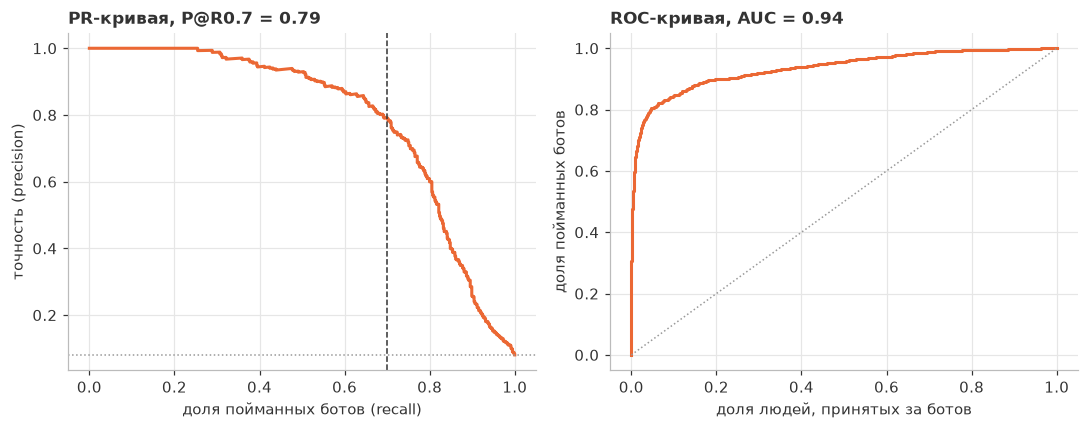

In [24]:
from sklearn.metrics import precision_recall_curve, roc_curve

yo = y.loc[oof_cf.index].astype(int).values
prec, rec, _ = precision_recall_curve(yo, oof_cf["p"].values)
fpr, tpr, _ = roc_curve(yo, oof_cf["p"].values)

_, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(rec, prec, color=BOT, lw=2)
axes[0].axvline(0.7, color=INK, ls="--", lw=1)
axes[0].axhline(yo.mean(), color="#999999", ls=":", lw=1)
axes[0].set_xlabel("доля пойманных ботов (recall)")
axes[0].set_ylabel("точность (precision)")
axes[0].set_title(f"PR-кривая, P@R0.7 = {precision_at_recall(yo, oof_cf['p'].values):.2f}")
axes[1].plot(fpr, tpr, color=BOT, lw=2)
axes[1].plot([0, 1], [0, 1], color="#999999", ls=":", lw=1)
axes[1].set_xlabel("доля людей, принятых за ботов")
axes[1].set_ylabel("доля пойманных ботов")
axes[1].set_title(f"ROC-кривая, AUC = {roc_auc_score(yo, oof_cf['p'].values):.2f}")
plt.tight_layout()
plt.show()

Точность около 0,9 и выше держится примерно до 55% пойманных ботов, на уровне 70% около 0,79, дальше быстро падает: остаются боты, которых трудно отличить от людей. ROC-AUC 0,94.

Важность признаков: встроенная оценка CatBoost (на сколько в среднем меняется предсказание при изменении признака), модель обучена на всём train. Топ-15.

In [25]:
model = make_model("cat", CAT_PARAMS)
Zf = prep(XA, FINAL_COLS, "cat")
model.fit(Zf[is_train], y[is_train].astype(int), cat_features=[c for c in CAT_COLS if c in FINAL_COLS])
importance = pd.Series(model.get_feature_importance(), index=FINAL_COLS).sort_values(ascending=False) / 100
display(importance.head(15).round(3).to_frame("важность"))

,важность
ptr_x_std,0.055
step_mean,0.048
gap_lt60,0.043
px_max,0.042
edge_share,0.036
gap_lt30,0.034
n_events,0.034
max_page,0.031
gap_p75,0.028
pop_mean,0.027


Наверху признаки курсора (разброс x, шаг, края экрана) и тайминга (доли коротких пауз), затем число событий, глубина выдачи и популярность объявлений.

## Итог

- **Качество:** P@R0.7 около 0,79 на трёх блоках проверки по времени и на другой схеме (5 блоков). На базовых признаках было около 0,67, у baseline из quickstart около 0,10, у константы 0,08.
- **Что дало прирост:** популярность объявлений (боты открывают общие объявления) и подробные признаки курсора (на web разброс положения курсора почти разделяет классы). Подробный тайминг помогает на мобильных, но прирост нестабилен.
- **Что не помогло:** доли категорий и городов, отдельная модель для мобильных.
- **Модель:** CatBoost (глубина 6), на итоговом наборе лучше LightGBM на всех блоках.
- **Слабое место — мобильные боты:** AUC внутри мобильных 0,86, но при общем пороге ловится примерно половина.
- **Неопределённость:** блоков мало, разброс 0,02–0,1, различия меньше 0,02 не значимы.